In [1]:
# CELL 1 — Install and verify OptiCore dependencies
%pip install -q ultralytics fastapi "uvicorn[standard]" pyngrok opencv-python-headless websockets

import sys, subprocess
subprocess.check_call([sys.executable, "-m", "pip", "show", "ultralytics"])

import torch, cv2, numpy as np, fastapi, uvicorn, ultralytics, pyngrok
print("=" * 40)
print("OPTICORE ENVIRONMENT READY")
print("=" * 40)
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Ultralytics:", ultralytics.__version__)
print("OpenCV:", cv2.__version__)
print("FastAPI:", fastapi.__version__)
print("Uvicorn:", uvicorn.__version__)
print("pyngrok:", pyngrok.__version__)
assert torch.cuda.is_available(), "Enable GPU in Kaggle Notebook Settings before continuing."
print("Cell 1 completed successfully.")

Note: you may need to restart the kernel to use updated packages.
Name: ultralytics
Version: 8.4.194
Summary: Ultralytics YOLO 🚀 for SOTA object detection, instance segmentation, semantic segmentation, depth estimation, classification, pose estimation, oriented object detection, and multi-object tracking.
Home-page: https://ultralytics.com
Author: 
Author-email: Glenn Jocher <glenn.jocher@ultralytics.com>, Jing Qiu <jing.qiu@ultralytics.com>
License: AGPL-3.0
Location: /usr/local/lib/python3.13/dist-packages
Requires: matplotlib, numpy, nvidia-ml-py, opencv-python, pillow, polars, psutil, pyyaml, requests, torch, torchvision, ultralytics-platform, ultralytics-thop
Required-by: 
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
OPTICORE ENVIRONMENT 

In [2]:
# CELL 2 — Load existing OptiCore model and initialize tracking / metrics
import os, time, threading
import numpy as np
import torch
from collections import Counter, defaultdict, deque
from dataclasses import dataclass, field
from ultralytics import YOLO

MODEL_PATH = (
    "/kaggle/input/models/"
    "dharshan8197/opticore/pytorch/default/1/best.pt"
)
if not os.path.isfile(MODEL_PATH):
    raise FileNotFoundError(
        f"Model not found: {MODEL_PATH}\n"
        "Check the attached Kaggle model input path."
    )

DEVICE = 0 if torch.cuda.is_available() else "cpu"
IMGSZ = 640
CONFIDENCE = 0.25
MAX_FRAME_WIDTH = 640
JPEG_QUALITY = 65

print("Loading OptiCore YOLO model...")
model = YOLO(MODEL_PATH)
CLASS_NAMES = model.names

dummy_frame = np.zeros((480, 640, 3), dtype=np.uint8)
start = time.perf_counter()
with torch.inference_mode():
    model.predict(source=dummy_frame, imgsz=IMGSZ, conf=CONFIDENCE,
                  device=DEVICE, verbose=False)
print("Warm-up:", round(time.perf_counter() - start, 2), "seconds")

INFERENCE_LOCK = threading.Lock()
CURRENT_COUNTS = Counter()
UNIQUE_TRACKS = defaultdict(set)
METRICS = {
    "frames_processed": 0,
    "last_inference_ms": 0.0,
    "avg_inference_ms": 0.0,
    "fps_ema": 0.0,
    "frames_rejected": 0,
    "last_inference_unix": None,
}
METRICS_LOCK = threading.Lock()

# Per-track temporal history for image-only risk heuristics.
@dataclass
class TrackHistory:
    samples: deque = field(default_factory=lambda: deque(maxlen=8))
    last_seen: float = field(default_factory=time.time)
    last_alert_time: float = 0.0
    last_alert_priority: str = ""
    last_risk: float = 0.0
    last_position: str = "ahead"
    last_class: str = ""

TRACK_HISTORY = {}
TRACK_HISTORY_LOCK = threading.Lock()
ALERT_HISTORY = deque(maxlen=200)
ALERT_HISTORY_LOCK = threading.Lock()
ALERT_COOLDOWN_SECONDS = 8.0
ALERT_ESCALATION_DELTA = 18.0
# Class rank is deliberately stronger than confidence. Lower number = more important.
# Confidence is used only to order detections within the same class rank.
CLASS_PRIORITY = {
    "car": 1, "bus": 1, "truck": 1, "motorcycle": 1, "bicycle": 1,
    "person": 2,
    "obstacle": 3, "stairs": 3, "pothole": 3, "crack": 3, "manhole": 3,
    "door": 4,
    "traffic_light": 5, "traffic_sign": 5,
    "animal": 5,
    "pole": 6, "tree": 6, "waste_container": 6,
    "bench": 6, "chair": 6,
}
# Doors and stairs are persistent navigation landmarks: repeat every 2s while visible.
PERSISTENT_LANDMARKS = {"door", "stairs"}
LANDMARK_REPEAT_SECONDS = 2.0


# This server version deliberately allows one active video producer.
PRODUCER_LOCK = threading.Lock()
PRODUCER_ACTIVE = False
PRODUCER_ID = None
SERVER_STARTED_AT = time.time()

# Latest processed frame buffer for the Kaggle notebook viewer.
LATEST_FRAME_LOCK = threading.Lock()
LATEST_ANNOTATED_JPEG = None
LATEST_FRAME_TIME = None
RECEIVED_FRAME_COUNT = 0

print("Model loaded successfully.")
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Classes:", len(CLASS_NAMES))
print("Class names:", CLASS_NAMES)
print("Tracking history and prioritization initialized.")

Loading OptiCore YOLO model...
Warm-up: 6.19 seconds
Model loaded successfully.
GPU: Tesla T4
Classes: 20
Class names: {0: 'person', 1: 'car', 2: 'bus', 3: 'truck', 4: 'motorcycle', 5: 'bicycle', 6: 'animal', 7: 'door', 8: 'stairs', 9: 'pothole', 10: 'crack', 11: 'manhole', 12: 'traffic_light', 13: 'traffic_sign', 14: 'pole', 15: 'tree', 16: 'bench', 17: 'chair', 18: 'waste_container', 19: 'obstacle'}
Tracking history and prioritization initialized.


In [3]:
# CELL 3 — FastAPI, YOLO + ByteTrack, image-based prioritization, monitoring API

import asyncio
import base64
import json
import logging
import time
import uuid
import cv2
import numpy as np
import torch
from fastapi import FastAPI, WebSocket, WebSocketDisconnect
from fastapi.responses import HTMLResponse, JSONResponse

logger = logging.getLogger("opticore")
app = FastAPI(title="OptiCore Vision API", version="1.1.0")

def clamp01(value):
    return max(0.0, min(1.0, float(value)))


def infer_position(center_x, width):
    """Image-relative location only; not a world-coordinate estimate."""
    relative_x = float(center_x) / max(1, width)
    if relative_x < 0.38:
        return "left"
    if relative_x > 0.62:
        return "right"
    return "ahead"


def class_priority(name):
    return CLASS_PRIORITY.get(str(name).strip().lower(), 7)


def priority_for_track(track_id, name, box, width, height, now):
    x1, y1, x2, y2 = map(float, box)
    box_w, box_h = max(1.0, x2-x1), max(1.0, y2-y1)
    center_x, center_y = (x1+x2)/2, (y1+y2)/2
    area = box_w * box_h
    position = infer_position(center_x, width)
    nx, ny = center_x/max(1,width), center_y/max(1,height)
    centrality = clamp01(1.0 - abs(nx - 0.5)/0.5)
    lower_region = clamp01((ny - 0.20)/0.70)
    path_relevance = clamp01(0.65*centrality + 0.35*lower_region)
    normalized_name = str(name).strip().lower()

    with TRACK_HISTORY_LOCK:
        hist = TRACK_HISTORY.setdefault(int(track_id), TrackHistory())
        hist.samples.append((now, center_x, center_y, area))
        hist.last_seen = now
        hist.last_class = normalized_name
        hist.last_position = position
        samples = list(hist.samples)
        prior_risk = hist.last_risk
        last_alert_time = hist.last_alert_time
        last_alert_priority = hist.last_alert_priority

    motion_score = growth_score = 0.0
    dx_norm = dy_norm = 0.0
    if len(samples) >= 3:
        dt = max(0.05, samples[-1][0] - samples[0][0])
        dx_norm = (samples[-1][1] - samples[0][1]) / max(1, width)
        dy_norm = (samples[-1][2] - samples[0][2]) / max(1, height)
        motion_score = clamp01(((abs(dx_norm) + abs(dy_norm)) / dt) / 1.2)
        old_area = max(1.0, samples[0][3])
        new_area = max(1.0, samples[-1][3])
        area_growth_per_second = (new_area/old_area - 1.0) / dt
        growth_score = clamp01(area_growth_per_second / 1.5)

    # Only describe an approach when the tracked box is visibly growing over time.
    approaching = growth_score >= 0.16 and len(samples) >= 3
    if approaching:
        if position == "left":
            approach_direction = "from your left"
        elif position == "right":
            approach_direction = "from your right"
        else:
            approach_direction = "head-on"
    else:
        approach_direction = None

    is_vehicle = normalized_name in {"car", "truck", "bus", "motorcycle", "bicycle"}
    approach_score = clamp01(0.65*growth_score + 0.35*motion_score*(1.0 if is_vehicle else 0.45))
    persistence = clamp01(len(samples)/5.0)
    risk_score = 100.0*(0.40*approach_score + 0.30*path_relevance + 0.15*motion_score + 0.15*persistence)

    if risk_score >= 78 and approach_score >= 0.50 and path_relevance >= 0.55:
        risk_priority = "P1"
    elif risk_score >= 57 and (motion_score >= 0.15 or path_relevance >= 0.72):
        risk_priority = "P2"
    elif risk_score >= 32:
        risk_priority = "P3"
    else:
        risk_priority = "P4"

    # Repeat selected continuously visible classes every 3 seconds.
    # Other classes remain deduplicated unless risk materially escalates.
    REPEAT_ALERT_CLASSES = {"door", "stairs", "pole", "obstacle", "person"}
    repeat_class = normalized_name in REPEAT_ALERT_CLASSES
    cooldown = 3.0 if repeat_class else ALERT_COOLDOWN_SECONDS
    first_alert = not last_alert_priority
    cooldown_elapsed = now - last_alert_time >= cooldown
    material_escalation = risk_score >= prior_risk + ALERT_ESCALATION_DELTA
    alert_candidate = first_alert or (
        cooldown_elapsed and (repeat_class or material_escalation)
    )

    with TRACK_HISTORY_LOCK:
        hist.last_risk = risk_score
        if alert_candidate:
            hist.last_alert_time = now
            hist.last_alert_priority = risk_priority

    return {
        "position": position,
        "approaching": approaching,
        "approach_direction": approach_direction,
        "class_priority": class_priority(normalized_name),
        "area_ratio": round(area/max(1, width*height), 4),
        "priority": risk_priority,
        "risk_score": round(risk_score, 1),
        "motion_score": round(motion_score, 3),
        "apparent_growth_score": round(growth_score, 3),
        "path_relevance": round(path_relevance, 3),
        "approach_estimate": round(approach_score, 3),
        "alert_candidate": alert_candidate,
        "distance_available": False,
    }

def process_frame(frame):
    start = time.perf_counter()
    now = time.time()

    with INFERENCE_LOCK, torch.inference_mode():
        results = model.track(
            source=frame, persist=True, tracker="bytetrack.yaml",
            imgsz=IMGSZ, conf=CONFIDENCE, device=DEVICE, verbose=False,
        )
        result = results[0]
        annotated = result.plot()
        detections = []
        frame_counts = Counter()
        height, width = frame.shape[:2]

        boxes = result.boxes
        if boxes is not None and len(boxes):
            coords = boxes.xyxy.cpu().numpy()
            scores = boxes.conf.cpu().numpy()
            classes = boxes.cls.cpu().numpy().astype(int)
            track_ids = (
                boxes.id.int().cpu().tolist()
                if boxes.id is not None else [None] * len(coords)
            )

            for box, score, cls_id, track_id in zip(coords, scores, classes, track_ids):
                x1, y1, x2, y2 = map(float, box)
                name = str(CLASS_NAMES[int(cls_id)])
                frame_counts[name] += 1
                if track_id is not None:
                    UNIQUE_TRACKS[name].add(int(track_id))
                det = {
                    "name": name,
                    "confidence": round(float(score), 3),
                    "id": track_id,
                    "position": infer_position((x1+x2)/2, width),
                    "class_priority": class_priority(name),
                    "area_ratio": round(max(0,x2-x1)*max(0,y2-y1)/(width*height), 4),
                    "priority": "P4",
                    "risk_score": 0.0,
                    "approaching": False,
                    "approach_direction": None,
                    "alert_candidate": False,
                    "distance_available": False,
                }
                if track_id is not None:
                    det.update(priority_for_track(int(track_id), name, box, width, height, now))
                detections.append(det)

        CURRENT_COUNTS.clear()
        CURRENT_COUNTS.update(frame_counts)

    elapsed_ms = (time.perf_counter() - start) * 1000
    with METRICS_LOCK:
        METRICS["frames_processed"] += 1
        METRICS["last_inference_ms"] = round(elapsed_ms, 2)
        previous = METRICS["avg_inference_ms"]
        METRICS["avg_inference_ms"] = round(
            elapsed_ms if previous == 0 else previous*0.9 + elapsed_ms*0.1, 2
        )
        METRICS["last_inference_unix"] = now
        instantaneous_fps = 1000.0/max(1.0, elapsed_ms)
        old_fps = METRICS["fps_ema"]
        METRICS["fps_ema"] = round(
            instantaneous_fps if old_fps == 0 else old_fps*0.9 + instantaneous_fps*0.1, 2
        )

    detections.sort(key=lambda d: (int(d.get("class_priority", 7)), -float(d.get("confidence", 0.0))))

    counts = {
        "current": dict(CURRENT_COUNTS),
        "unique_tracked": {name: len(ids) for name, ids in UNIQUE_TRACKS.items()},
    }
    # Build short, natural-language alerts. Confidence remains available as metadata,
    # but it is never included in the spoken sentence.
    alerts = []
    GENERIC_OBSTACLE_CLASSES = {
        "traffic_light", "traffic_sign", "pole", "tree", "bench", "chair",
        "waste_container", "obstacle",
    }
    APPROACH_CLASSES = {"car", "truck", "bus", "motorcycle", "bicycle", "person"}

    for d in detections:
        if not d.get("alert_candidate"):
            continue

        name = str(d.get("name", "obstacle")).strip().lower()
        position = d.get("position", "ahead")
        location = {"left": "to your left", "right": "to your right"}.get(position, "ahead")

        if name in GENERIC_OBSTACLE_CLASSES:
            message = f"There is an obstacle {location}."
        elif name in APPROACH_CLASSES and d.get("approaching") and d.get("approach_direction"):
            direction = str(d["approach_direction"]).strip().lower()
            if direction == "head-on":
                message = f"A {name} is approaching head-on."
            elif direction in {"from your left", "from your right"}:
                message = f"A {name} is approaching {direction}."
            elif direction == "left":
                message = f"A {name} is approaching from your left."
            elif direction == "right":
                message = f"A {name} is approaching from your right."
            else:
                message = f"A {name} is approaching."
        elif name in {"door", "stairs"}:
            message = f"There {'are' if name == 'stairs' else 'is'} {name} {location}."
        else:
            spoken_name = name.replace("_", " ")
            article = "an" if spoken_name[:1] in "aeiou" else "a"
            message = f"There is {article} {spoken_name} {location}."

        alert = {
            "timestamp": now,
            "track_id": d.get("id"),
            "name": name,
            "confidence": d.get("confidence", 0.0),
            "class_priority": d.get("class_priority", 7),
            "position": position,
            "approaching": d.get("approaching", False),
            "approach_direction": d.get("approach_direction"),
            "priority": d.get("priority", "P4"),
            "risk_score": d.get("risk_score", 0),
            "message": message,
        }
        alerts.append(alert)
        with ALERT_HISTORY_LOCK:
            ALERT_HISTORY.appendleft(alert)

    return annotated, detections, elapsed_ms, counts, alerts

@app.get("/")
async def browser_page():
    return HTMLResponse(BROWSER_HTML)

@app.get("/health")
async def health():
    with METRICS_LOCK:
        metrics = dict(METRICS)
    return {
        "status": "ok", "model_loaded": model is not None,
        "device": str(DEVICE), "classes": len(CLASS_NAMES),
        "tracker": "bytetrack.yaml", "imgsz": IMGSZ, **metrics
    }

@app.get("/status")
async def status():
    with METRICS_LOCK:
        metrics = dict(METRICS)
    return {
        "service": "OptiCore Vision API", "version": "1.1.0",
        "model_loaded": model is not None, "device": str(DEVICE),
        "gpu_available": bool(torch.cuda.is_available()),
        "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
        "producer_active": PRODUCER_ACTIVE, "producer_id": PRODUCER_ID,
        "uptime_seconds": round(time.time()-SERVER_STARTED_AT, 1),
        "metrics": metrics,
        "priority_engine": "image-only heuristic",
        "speech_policy": "client-side sequential queue + server-side deduplication",
    }

@app.get("/metrics")
async def metrics():
    with METRICS_LOCK:
        return dict(METRICS)

@app.get("/events")
async def events(limit: int = 20):
    limit = max(1, min(100, limit))
    with ALERT_HISTORY_LOCK:
        return {"events": list(ALERT_HISTORY)[:limit]}

@app.websocket("/ws/video")
async def video_stream(websocket: WebSocket):
    global PRODUCER_ACTIVE, PRODUCER_ID
    global LATEST_ANNOTATED_JPEG, LATEST_FRAME_TIME, RECEIVED_FRAME_COUNT
    await websocket.accept()

    # Single-producer guard: this version's persistent model.track state is shared.
    with PRODUCER_LOCK:
        if PRODUCER_ACTIVE:
            await websocket.send_text(json.dumps({
                "type": "error", "code": "producer_busy",
                "message": "Another camera stream is active. Stop it before connecting this camera."
            }))
            await websocket.close(code=1013)
            return
        PRODUCER_ACTIVE = True
        PRODUCER_ID = str(uuid.uuid4())[:8]

    this_producer = PRODUCER_ID
    logger.info("Camera producer connected: %s", this_producer)
    try:
        while True:
            payload = await websocket.receive_bytes()
            if len(payload) > 8 * 1024 * 1024:
                with METRICS_LOCK:
                    METRICS["frames_rejected"] += 1
                continue
            frame = cv2.imdecode(np.frombuffer(payload, dtype=np.uint8), cv2.IMREAD_COLOR)
            if frame is None:
                continue
            height, width = frame.shape[:2]
            if width > MAX_FRAME_WIDTH:
                frame = cv2.resize(
                    frame, (MAX_FRAME_WIDTH, int(height*MAX_FRAME_WIDTH/width)),
                    interpolation=cv2.INTER_AREA
                )
            annotated, detections, inference_ms, counts, alerts = await asyncio.to_thread(process_frame, frame)
            ok, encoded = cv2.imencode(
                ".jpg", annotated, [cv2.IMWRITE_JPEG_QUALITY, JPEG_QUALITY]
            )
            if not ok:
                continue

            # Keep only the latest processed JPEG for Kaggle's notebook viewer.
            # This does not create another producer or change the WebSocket protocol.
            jpeg_bytes = encoded.tobytes()
            with LATEST_FRAME_LOCK:
                LATEST_ANNOTATED_JPEG = jpeg_bytes
                LATEST_FRAME_TIME = time.time()
                RECEIVED_FRAME_COUNT += 1

            await websocket.send_text(json.dumps({
                "image": base64.b64encode(encoded.tobytes()).decode("ascii"),
                "detections": detections, "counts": counts,
                "alerts": alerts, "inference_ms": round(inference_ms, 2),
                "stream_id": this_producer, "timestamp": time.time(),
            }))
    except WebSocketDisconnect:
        logger.info("OptiCore client disconnected: %s", this_producer)
    except Exception:
        logger.exception("WebSocket processing failed")
        try:
            await websocket.close(code=1011)
        except Exception:
            pass
    finally:
        with PRODUCER_LOCK:
            PRODUCER_ACTIVE = False
            PRODUCER_ID = None
        # Prune old track history to keep memory bounded.
        cutoff = time.time() - 30
        with TRACK_HISTORY_LOCK:
            for tid in list(TRACK_HISTORY):
                if TRACK_HISTORY[tid].last_seen < cutoff:
                    del TRACK_HISTORY[tid]

print("OptiCore API created.")
print("Routes:", [getattr(route, "path", "?") for route in app.routes])

OptiCore API created.
Routes: ['/openapi.json', '/docs', '/docs/oauth2-redirect', '/redoc', '/', '/health', '/status', '/metrics', '/events', '/ws/video']


In [4]:
# CELL 4 — OptiCore browser UI with positions, counters, and TTS

BROWSER_HTML = r"""
<!DOCTYPE html>
<html>
<head>
<meta name="viewport" content="width=device-width,initial-scale=1">
<title>OptiCore Live Vision</title>
<style>
*{box-sizing:border-box}
:root{color-scheme:dark;--bg:#050914;--panel:rgba(13,23,43,.70);--panel2:rgba(10,18,35,.74);--line:rgba(112,158,220,.22);--text:#f4f8ff;--muted:#a8b8d0;--blue:#68adff;--blue2:#2878ed;--white:#fff;--green:#55ddb0;--shadow:0 18px 50px rgba(0,0,0,.28)}
body{margin:0;padding:clamp(16px,3vw,36px);background:radial-gradient(ellipse at 12% -10%,rgba(31,102,196,.28),transparent 42%),radial-gradient(ellipse at 100% 10%,rgba(26,75,145,.18),transparent 38%),linear-gradient(145deg,#050914,#080f1f 58%,#050914);color:var(--text);font:15px/1.55 Inter,ui-sans-serif,system-ui,-apple-system,BlinkMacSystemFont,"Segoe UI",sans-serif;min-height:100vh}
header{display:flex;align-items:center;justify-content:space-between;gap:16px;flex-wrap:wrap;margin:0 auto 22px;max-width:1500px}
h2{margin:0;font-size:clamp(25px,3vw,36px);letter-spacing:-.045em;font-weight:760}h3{margin:0 0 15px;font-size:14px;letter-spacing:.04em;font-weight:750;color:#eaf2ff}
.brand{display:flex;align-items:center;gap:13px}.logo{width:46px;height:46px;border-radius:15px;display:grid;place-items:center;background:linear-gradient(145deg,#eaf4ff,#73b7ff 48%,#2475e8);color:#061225;font-weight:950;font-size:20px;box-shadow:0 8px 28px rgba(54,139,255,.25)}.eyebrow{color:var(--blue);font-size:10px;font-weight:850;letter-spacing:.19em;text-transform:uppercase;margin-bottom:3px}
body>div,body>.row{max-width:1500px;margin-left:auto;margin-right:auto}
.panel{background:linear-gradient(135deg,rgba(20,34,59,.76),rgba(8,16,32,.68));backdrop-filter:blur(18px) saturate(135%);-webkit-backdrop-filter:blur(18px) saturate(135%);border:1px solid var(--line);padding:20px;border-radius:20px;margin:13px 0;box-shadow:var(--shadow),inset 0 1px 0 rgba(255,255,255,.035)}
.controls{display:flex;align-items:center;gap:10px;flex-wrap:wrap}.row{display:grid;grid-template-columns:minmax(0,1.15fr) minmax(300px,1fr);gap:14px}.feed{position:relative;overflow:hidden;background:#030711;border-radius:14px;border:1px solid var(--line)}.feed video,.feed canvas{display:block;width:100%;height:auto;aspect-ratio:4/3;object-fit:contain;background:#030711}
.pill{display:inline-flex;align-items:center;gap:8px;border:1px solid var(--line);background:rgba(10,20,39,.75);padding:8px 12px;border-radius:999px;font-size:12px;color:#d8e7fc}.dot{width:7px;height:7px;border-radius:50%;background:#65758d}.dot.on{background:var(--green);box-shadow:0 0 13px rgba(85,221,176,.6)}
button,select{padding:11px 15px;border-radius:11px;border:1px solid rgba(115,164,230,.32);background:rgba(18,36,64,.86);color:var(--text);font:inherit;outline:none}button{cursor:pointer;font-weight:750;transition:transform .16s,border-color .16s,background .16s}button:hover{border-color:var(--blue);transform:translateY(-1px)}button:disabled{opacity:.48;cursor:not-allowed}#start{background:linear-gradient(135deg,#83c4ff,#4c98ff 55%,#2c75e8);border-color:transparent;color:#041225;box-shadow:0 7px 22px rgba(51,133,245,.2)}#stop{background:rgba(255,255,255,.055)}label{color:#d5e2f5}input[type=checkbox]{accent-color:var(--blue);width:15px;height:15px;vertical-align:middle}
.stats{display:grid;grid-template-columns:repeat(4,minmax(0,1fr));gap:11px}.metric{background:linear-gradient(135deg,rgba(16,30,53,.78),rgba(7,15,30,.72));border:1px solid var(--line);border-radius:15px;padding:15px}.metric span{display:block;color:var(--muted);font-size:11px;font-weight:650;letter-spacing:.04em;text-transform:uppercase}.metric strong{display:block;margin-top:6px;font-size:23px;letter-spacing:-.03em;font-variant-numeric:tabular-nums}
.muted{color:var(--muted);font-size:13px}table{border-collapse:collapse;width:100%;margin-top:8px}th,td{text-align:left;padding:11px 9px;border-bottom:1px solid rgba(112,158,220,.14)}th{font-size:10px;text-transform:uppercase;letter-spacing:.12em;color:#9eb4d2}td{font-size:13px;color:#e2ecfa}tbody tr:hover{background:rgba(74,142,230,.055)}
.detections{display:grid;gap:8px;list-style:none;padding:0;margin:0}.detections li{display:flex;justify-content:space-between;align-items:center;gap:12px;padding:13px 14px;background:rgba(7,16,32,.58);border:1px solid rgba(112,158,220,.17);border-radius:13px}.className{font-weight:760}.meta{color:var(--muted);font-size:12px;text-align:right}.priority{font-size:10px;font-weight:900;letter-spacing:.06em;border-radius:7px;padding:5px 7px;background:rgba(100,140,190,.15);color:#dceaff}.priority.p1{background:rgba(255,95,125,.13);color:#ffb6c4}.priority.p2{background:rgba(255,190,88,.13);color:#ffdfa8}.sectionGrid{display:grid;grid-template-columns:1fr 1fr;gap:14px}.empty{color:var(--muted);padding:12px}.muted strong{color:var(--text)}
@media(max-width:900px){.row{grid-template-columns:1fr}.stats{grid-template-columns:repeat(2,minmax(0,1fr))}}
@media(max-width:560px){body{padding:12px}.panel{padding:14px;border-radius:16px}.sectionGrid{grid-template-columns:1fr}.stats{gap:7px}.metric{padding:12px}.metric strong{font-size:19px}.detections li{align-items:flex-start}.meta{max-width:48%}}
@media(prefers-reduced-motion:reduce){*{transition:none!important;scroll-behavior:auto!important}}
</style>
</head>
<body>
<header><div class="brand"><div class="logo">O</div><div><div class="eyebrow">Assistive perception system</div><h2>OptiCore <span style="color:var(--blue)">Live Vision</span></h2></div></div><div class="pill"><span id="statusDot" class="dot"></span><span id="status">Stopped</span></div></header>

<div class="panel">
  <label for="camera">Camera:</label>
  <select id="camera"></select>
  <button id="start">Start camera</button>
  <button id="stop">Stop</button>
  <label><input id="speech" type="checkbox"> Voice alerts</label>
  <p class="muted">Position is relative to the camera image.</p>
</div>

<div class="row">
  <div class="panel">
    <h3>Camera feed</h3>
    <video id="video" autoplay muted playsinline></video>
  </div>
  <div class="panel">
    <h3>Annotated output</h3>
    <canvas id="output" width="640" height="480"></canvas>
  </div>
</div>

<div class="panel stats">
  <div class="metric"><span>Frames sent</span><strong id="sent">0</strong></div>
  <div class="metric"><span>Responses</span><strong id="received">0</strong></div>
  <div class="metric"><span>Round trip</span><strong id="rtt">—</strong></div>
  <div class="metric"><span>Inference</span><strong id="inference">—</strong></div>
</div>

<div class="panel">
  <h3>Current visible counts</h3>
  <table>
    <thead><tr><th>Class</th><th>Count</th></tr></thead>
    <tbody id="currentCounts"><tr><td colspan="2">Waiting for detections</td></tr></tbody>
  </table>
</div>

<div class="panel">
  <h3>Unique tracked objects this session</h3>
  <table>
    <thead><tr><th>Class</th><th>Unique IDs</th></tr></thead>
    <tbody id="uniqueCounts"><tr><td colspan="2">Waiting for tracks</td></tr></tbody>
  </table>
</div>

<div class="panel">
  <h3>Detections and positions</h3>
  <ul id="detections" class="detections"><li class="empty">Waiting for camera</li></ul>
</div>

<canvas id="capture" width="640" height="480" hidden></canvas>

<script>
const $ = id => document.getElementById(id);
const video = $("video");
const output = $("output");
const ctx = output.getContext("2d");
const capture = $("capture");
const cctx = capture.getContext("2d");

let stream = null, ws = null, timer = null;
let busy = false, sent = 0, received = 0;
let sentAt = 0, sessionId = 0;

async function refreshCameras() {
  const devices = await navigator.mediaDevices.enumerateDevices();
  const select = $("camera");
  const old = select.value;
  select.innerHTML = "";

  devices.filter(d => d.kind === "videoinput").forEach((d, i) => {
    const opt = document.createElement("option");
    opt.value = d.deviceId;
    opt.textContent = d.label || `Camera ${i + 1}`;
    select.appendChild(opt);
  });

  if ([...select.options].some(o => o.value === old)) select.value = old;
}

function renderTable(id, counts) {
  const tbody = $(id);
  tbody.replaceChildren();
  const entries = Object.entries(counts || {}).sort((a,b) => b[1]-a[1]);

  if (!entries.length) {
    const tr = document.createElement("tr");
    const td = document.createElement("td");
    td.colSpan = 2;
    td.textContent = "None detected";
    tr.appendChild(td);
    tbody.appendChild(tr);
    return;
  }

  for (const [name, count] of entries) {
    const tr = document.createElement("tr");
    const first = document.createElement("td");
    const second = document.createElement("td");
    first.textContent = name;
    second.textContent = count;
    tr.append(first, second);
    tbody.appendChild(tr);
  }
}

// Speech is deliberately event-driven, not detection-per-frame.
const spokenKeys = new Map();
let speechQueue = [];
let speaking = false;
let activeSpeechPriority = 99;
let activeUtterance = null;
const ALERT_COOLDOWN_MS = 8000;
const REPEAT_ALERT_MS = 3000;
const REPEAT_ALERT_CLASSES = new Set(["door", "stairs", "pole", "obstacle", "person"]);
function priorityRank(priority) { return ({P1:1, P2:2, P3:3, P4:4})[priority] || 99; }
function classRank(alert) { return Number(alert.class_priority ?? 7); }

function announceAlerts(alerts) {
  if (!$("speech").checked || !window.speechSynthesis) return;
  const now = Date.now();
  const candidates = (alerts || []).slice().sort((a,b) =>
    classRank(a) - classRank(b) || priorityRank(a.priority) - priorityRank(b.priority) ||
    Number(b.confidence || 0) - Number(a.confidence || 0)
  );

  for (const alert of candidates) {
    const repeatClass = REPEAT_ALERT_CLASSES.has(String(alert.name || "").toLowerCase());
    const key = `${alert.track_id ?? "unknown"}|${String(alert.name || "").toLowerCase()}|${alert.position || "ahead"}|${alert.approach_direction || "stationary"}`;
    const previous = spokenKeys.get(key) || 0;
    const cooldown = repeatClass ? REPEAT_ALERT_MS : ALERT_COOLDOWN_MS;
    if (now - previous < cooldown) continue;
    spokenKeys.set(key, now);

    const rank = classRank(alert) * 10 + priorityRank(alert.priority);
    const item = {text: alert.message, rank, key};

    // A P1 warning may interrupt a lower-priority utterance. Otherwise queue.
    if (classRank(alert) === 1 && speaking && activeSpeechPriority > 12) {
      speechSynthesis.cancel();
      speaking = false;
      activeUtterance = null;
      speechQueue = speechQueue.filter(x => x.rank === 1);
    }

    // Do not accumulate stale repeated alerts; keep the queue short.
    if (!speechQueue.some(x => x.key === key)) {
      if (speechQueue.length >= 3) {
        const lowestIndex = speechQueue.reduce(
          (best, x, i, arr) => x.rank > arr[best].rank ? i : best, 0
        );
        if (rank < speechQueue[lowestIndex].rank) speechQueue.splice(lowestIndex, 1);
        else continue;
      }
      speechQueue.push(item);
      speechQueue.sort((a,b) => a.rank-b.rank);
    }
  }
  speakNext();
}

function speakNext() {
  if (speaking || !speechQueue.length || !$("speech").checked) return;
  const item = speechQueue.shift();
  speaking = true;
  activeSpeechPriority = item.rank;
  const utterance = new SpeechSynthesisUtterance(item.text);
  activeUtterance = utterance;
  utterance.rate = 1.05;
  utterance.onend = utterance.onerror = () => {
    if (activeUtterance === utterance) {
      speaking = false;
      activeUtterance = null;
      activeSpeechPriority = 99;
      speakNext();
    }
  };
  speechSynthesis.speak(utterance);
}

$("speech").addEventListener("change", () => {
  if (!$("speech").checked && window.speechSynthesis) {
    speechSynthesis.cancel();
    speechQueue = [];
    speaking = false;
    activeUtterance = null;
    activeSpeechPriority = 99;
  }
});

async function connect(mySession) {
  return new Promise((resolve, reject) => {
    const scheme = location.protocol === "https:" ? "wss:" : "ws:";
    const socket = new WebSocket(`${scheme}//${location.host}/ws/video`);
    ws = socket;

    socket.onopen = () => {
      $("status").textContent = "Connected";
      $("statusDot").classList.add("on");
      resolve();
    };
    socket.onerror = () => reject(Error("WebSocket connection failed"));
    socket.onclose = () => {
      if (mySession === sessionId) { $("status").textContent = "Disconnected"; $("statusDot").classList.remove("on"); }
    };

    socket.onmessage = async event => {
      if (mySession !== sessionId) return;

      try {
        const data = JSON.parse(event.data);
        if (data.type === "error") {
          $("status").textContent = data.message || data.code || "Server error";
          busy = false;
          return;
        }
        const bytes = Uint8Array.from(atob(data.image), c => c.charCodeAt(0));
        const bitmap = await createImageBitmap(new Blob([bytes], {type:"image/jpeg"}));
        ctx.drawImage(bitmap, 0, 0, output.width, output.height);
        bitmap.close();

        received++;
        $("received").textContent = received;
        $("rtt").textContent = Math.round(performance.now() - sentAt) + " ms";
        $("inference").textContent = Number(data.inference_ms).toFixed(1) + " ms";

        renderTable("currentCounts", data.counts?.current);
        renderTable("uniqueCounts", data.counts?.unique_tracked);

        const detections = (data.detections || []).slice().sort((a,b) =>
          Number(a.class_priority ?? 7)-Number(b.class_priority ?? 7) ||
          Number(b.confidence ?? 0)-Number(a.confidence ?? 0));
        const list = $("detections");
        list.replaceChildren();
        if (!detections.length) {
          const li = document.createElement("li"); li.className="empty";
          li.textContent = "No objects detected in the current frame"; list.appendChild(li);
        } else {
          for (const d of detections) {
            const li = document.createElement("li");
            const left = document.createElement("div");
            const name = document.createElement("div"); name.className="className";
            name.textContent = `${d.name} · ${d.position || "ahead"}`;
            const detail = document.createElement("div"); detail.className="muted";
            detail.textContent = `${d.id == null ? "" : "Track "+d.id}${d.approaching && d.approach_direction ? (d.id == null ? "" : " · ")+"apparent approach: "+d.approach_direction : ""}`;
            left.append(name,detail);
            const right = document.createElement("div"); right.className="meta";
            const badge = document.createElement("span"); badge.className="priority "+String(d.priority||"P4").toLowerCase(); badge.textContent=d.priority||"P4";
            const score = document.createElement("div"); score.textContent=`Risk heuristic ${d.risk_score ?? 0}`;
            right.append(badge,score); li.append(left,right); list.appendChild(li);
          }
        }

        announceAlerts(data.alerts || []);
      } catch (e) {
        console.error("Could not process server response:", e);
      } finally {
        if (mySession === sessionId) busy = false;
      }
    };
  });
}

function sendFrame() {
  if (busy || !stream || !ws || ws.readyState !== WebSocket.OPEN ||
      video.readyState < 2) return;

  busy = true;
  const currentSession = sessionId;
  cctx.drawImage(video, 0, 0, capture.width, capture.height);

  capture.toBlob(blob => {
    if (!blob || currentSession !== sessionId ||
        !ws || ws.readyState !== WebSocket.OPEN) {
      busy = false;
      return;
    }
    sentAt = performance.now();
    ws.send(blob);
    sent++;
    $("sent").textContent = sent;
  }, "image/jpeg", 0.65);
}

$("start").onclick = async () => {
  const currentSession = ++sessionId;
  try {
    $("start").disabled = true;
    const deviceId = $("camera").value;

    stream = await navigator.mediaDevices.getUserMedia({
      video: {
        ...(deviceId ? {deviceId:{exact:deviceId}} : {}),
        width:{ideal:640}, height:{ideal:480},
        frameRate:{ideal:20,max:24}
      },
      audio:false
    });

    if (currentSession !== sessionId) {
      stream.getTracks().forEach(t => t.stop());
      return;
    }

    video.srcObject = stream;
    await video.play();
    await refreshCameras();
    await connect(currentSession);
    timer = setInterval(sendFrame, 15);
  } catch (e) {
    $("status").textContent = e.message;
    $("start").disabled = false;
    console.error(e);
  }
};

$("stop").onclick = () => {
  sessionId++;
  if (timer) clearInterval(timer);
  timer = null;
  busy = false;
  if (ws) ws.close();
  ws = null;
  if (stream) stream.getTracks().forEach(t => t.stop());
  stream = null;
  video.srcObject = null;
  if (window.speechSynthesis) speechSynthesis.cancel();
  speechQueue = [];
  speaking = false;
  $("start").disabled = false;
  $("status").textContent = "Stopped";
  $("statusDot").classList.remove("on");
};

refreshCameras().catch(console.warn);
navigator.mediaDevices?.addEventListener?.("devicechange", refreshCameras);
</script>
</body>
</html>
"""

@app.get("/", response_class=HTMLResponse)
async def browser_page():
    return HTMLResponse(BROWSER_HTML)

print("Browser interface registered.")
print("Routes:", [getattr(route, "path", "?") for route in app.routes])

Browser interface registered.
Routes: ['/openapi.json', '/docs', '/docs/oauth2-redirect', '/redoc', '/', '/health', '/status', '/metrics', '/events', '/ws/video', '/']


Kaggle secret retrieved.
Old ngrok agent stopped.
Local API: {'status': 'ok', 'model_loaded': True, 'device': '0', 'classes': 20, 'tracker': 'bytetrack.yaml', 'imgsz': 640, 'frames_processed': 0, 'last_inference_ms': 0.0, 'avg_inference_ms': 0.0, 'fps_ema': 0.0, 'frames_rejected': 0, 'last_inference_unix': None}
New ngrok tunnel created.                                                                           

OPTICORE IS ONLINE
Browser URL:      https://distill-shrouded-washing.ngrok-free.dev
Health endpoint:  https://distill-shrouded-washing.ngrok-free.dev/health
Status endpoint:  https://distill-shrouded-washing.ngrok-free.dev/status
Metrics endpoint: https://distill-shrouded-washing.ngrok-free.dev/metrics
Events endpoint:  https://distill-shrouded-washing.ngrok-free.dev/events?limit=20
WebSocket URL:    wss://distill-shrouded-washing.ngrok-free.dev/ws/video
Model loaded:     True
Classes:          20
Tracker:          bytetrack.yaml

Starting the Kaggle live frame viewer.
Keep th

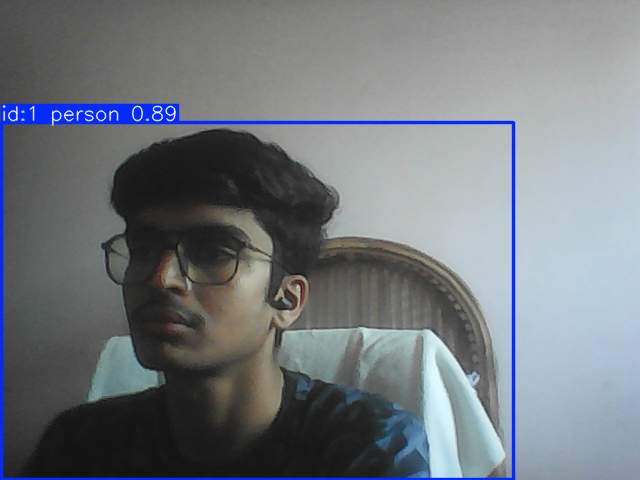

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 2 packages in 246ms
Prepared 1 package in 49ms
Installed 1 package in 5ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.7s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect



In [ ]:
# CELL 5 — OptiCore clean startup + Kaggle Secret authentication + ngrok

import os
import time
import json
import socket
import threading
import urllib.request
from pathlib import Path

import uvicorn
from kaggle_secrets import UserSecretsClient
from pyngrok import ngrok, conf

HOST = "0.0.0.0"
PORT = 8000

# -------------------------------------------------------
# 1. Retrieve the Kaggle secret (never print its value)
# -------------------------------------------------------
token = UserSecretsClient().get_secret("NGROK_AUTHTOKEN").strip()

if not token:
    raise RuntimeError(
        "NGROK_AUTHTOKEN is empty. Update the secret in Kaggle and rerun Cell 5."
    )

print("Kaggle secret retrieved.")

# -------------------------------------------------------
# 2. Stop the previous notebook-managed API server
# -------------------------------------------------------
old_server = globals().get("uvicorn_server")
old_thread = globals().get("uvicorn_thread")

if old_server is not None and old_thread is not None and old_thread.is_alive():
    print("Stopping previous OptiCore server...")
    old_server.should_exit = True
    old_thread.join(timeout=15)

    if old_thread.is_alive():
        raise RuntimeError(
            "Previous API server did not stop. Restart the Kaggle session "
            "and rerun Cells 1–5."
        )

# -------------------------------------------------------
# 3. Stop old ngrok agent/tunnels
# -------------------------------------------------------
try:
    ngrok.kill()
    time.sleep(1)
    print("Old ngrok agent stopped.")
except Exception as exc:
    print("Old ngrok agent cleanup:", str(exc)[:250])

# -------------------------------------------------------
# 4. Write a dedicated ngrok config with the current token
# -------------------------------------------------------
config_dir = Path("/tmp/opticore-ngrok")
config_dir.mkdir(parents=True, exist_ok=True)
config_path = config_dir / "ngrok.yml"

# JSON string quoting is valid YAML string quoting.
config_path.write_text(
    "version: '2'\nauthtoken: " + json.dumps(token) + "\n",
    encoding="utf-8",
)
os.chmod(config_path, 0o600)

ngrok_config = conf.PyngrokConfig(
    config_path=str(config_path),
    monitor_thread=False,
)

# -------------------------------------------------------
# 5. Start the API only if port 8000 is available
# -------------------------------------------------------
with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as sock:
    port_in_use = sock.connect_ex(("127.0.0.1", PORT)) == 0

if port_in_use:
    # It may be an API process not managed by this notebook.
    # Reuse it only if it is already a healthy OptiCore API.
    try:
        with urllib.request.urlopen(
            f"http://127.0.0.1:{PORT}/health", timeout=3
        ) as response:
            existing_health = json.loads(response.read().decode())
        if existing_health.get("status") != "ok":
            raise RuntimeError("Port 8000 is occupied by another service.")
        print("Reusing healthy OptiCore API on port 8000.")
    except Exception as exc:
        raise RuntimeError(
            "Port 8000 is occupied by an unmanaged process. Restart the "
            "Kaggle session, then rerun Cells 1–5."
        ) from exc
else:
    uvicorn_config = uvicorn.Config(
        app, host=HOST, port=PORT,
        log_level="warning", access_log=False,
    )
    uvicorn_server = uvicorn.Server(uvicorn_config)

    def _run_opticore():
        uvicorn_server.run()

    uvicorn_thread = threading.Thread(
        target=_run_opticore,
        daemon=True,
        name="opticore-uvicorn",
    )
    uvicorn_thread.start()

    existing_health = None
    for _ in range(40):
        if not uvicorn_thread.is_alive():
            raise RuntimeError("OptiCore API stopped during startup.")
        try:
            with urllib.request.urlopen(
                f"http://127.0.0.1:{PORT}/health", timeout=2
            ) as response:
                existing_health = json.loads(response.read().decode())
            break
        except Exception:
            time.sleep(0.5)

    if existing_health is None:
        raise RuntimeError("Local OptiCore health check failed.")

print("Local API:", existing_health)

# -------------------------------------------------------
# 6. Start a NEW ngrok tunnel using the dedicated config
# -------------------------------------------------------
try:
    tunnel = ngrok.connect(
        addr=PORT,
        proto="http",
        pyngrok_config=ngrok_config,
    )
    new_public_url = tunnel.public_url
    print("New ngrok tunnel created.")
except Exception as exc:
    print("\n❌ ngrok could not authenticate or create a tunnel.")
    print("Error:", str(exc)[:1800])
    print(
        "\nVerify NGROK_AUTHTOKEN in Kaggle Secrets against the current "
        "token in https://dashboard.ngrok.com/get-started/your-authtoken"
    )
    raise RuntimeError(
        "OptiCore is running locally, but no new public tunnel was created."
    ) from exc

# -------------------------------------------------------
# 7. Verify that the NEW public URL serves this API
# -------------------------------------------------------
public_health = None
last_error = None

for _ in range(12):
    try:
        request = urllib.request.Request(
            new_public_url + "/health",
            headers={"ngrok-skip-browser-warning": "true"},
        )
        with urllib.request.urlopen(request, timeout=10) as response:
            public_health = json.loads(response.read().decode())
        break
    except Exception as exc:
        last_error = str(exc)
        time.sleep(1)

if public_health is None or public_health.get("status") != "ok":
    try:
        ngrok.disconnect(new_public_url, pyngrok_config=ngrok_config)
    except Exception:
        pass
    raise RuntimeError(
        "Tunnel was created, but public health verification failed: "
        + str(last_error)
    )

# Save only the verified URL.
PUBLIC_URL = new_public_url

print("\n" + "=" * 54)
print("OPTICORE IS ONLINE")
print("=" * 54)
print("Browser URL:     ", PUBLIC_URL)
print("Health endpoint: ", PUBLIC_URL + "/health")
print("Status endpoint: ", PUBLIC_URL + "/status")
print("Metrics endpoint:", PUBLIC_URL + "/metrics")
print("Events endpoint: ", PUBLIC_URL + "/events?limit=20")
print("WebSocket URL:   ", PUBLIC_URL.replace("https://", "wss://") + "/ws/video")
print("Model loaded:    ", public_health.get("model_loaded"))
print("Classes:         ", public_health.get("classes"))
print("Tracker:         ", public_health.get("tracker"))
print("=" * 54)

# -------------------------------------------------------
# 8. Display frames actually received and processed by this server
# -------------------------------------------------------
from IPython.display import display, Image, HTML

print("\nStarting the Kaggle live frame viewer.")
print("Keep this cell running. Stop the viewer with the notebook interrupt button.")
frame_display = display(HTML("<b>Waiting for the remote camera to send frames...</b>"), display_id=True)
status_display = display(HTML("No frames received yet."), display_id=True)
last_displayed_count = -1

try:
    while True:
        with LATEST_FRAME_LOCK:
            jpeg_bytes = LATEST_ANNOTATED_JPEG
            frame_time = LATEST_FRAME_TIME
            frame_count = RECEIVED_FRAME_COUNT

        if jpeg_bytes is not None and frame_count != last_displayed_count:
            frame_display.update(Image(data=jpeg_bytes, format="jpeg"))
            age = max(0.0, time.time() - frame_time) if frame_time else 0.0
            status_display.update(HTML(
                "<b>OptiCore server frame viewer</b><br>"
                f"Processed frames: {frame_count}<br>"
                f"Latest frame age: {age:.2f} seconds<br>"
                f"Stream: {'LIVE' if age < 3.0 else 'STALE'}"
            ))
            last_displayed_count = frame_count
        elif jpeg_bytes is None:
            status_display.update(HTML(
                "Waiting for frames. Open the Browser URL printed above on the remote camera system, "
                "then click Start Camera."
            ))

        time.sleep(0.1)
except KeyboardInterrupt:
    print("Kaggle live frame viewer stopped. The notebook server may still be running.")
